# Bloco 1 - Escolha do Dataset
### **P1.** Qual dataset o grupo escolheu e por que ele foi preferido ao segundo candidato?
O dataset escolhido é o D5  Câmara dos  Deputados, API de dados abertos O dataset foi escolhido por se tratar de um período interessante dado o assunto.
### **P2.** Quantas fontes (arquivos, tabelas ou endpoints) ele possui e quantas linhas tem a maior delas?
São dois arquivos, com deputados e partidos, o maior sendo de deputados, contendo informações
### **P3.** Que problema de qualidade vocês já enxergaram apenas olhando uma amostra?

In [10]:
import os
import json
import requests
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import sqlite3

In [3]:
destino = 'DATA/bronze'

# Garante que a pasta 'DATA/bronze' seja criada caso ainda não exista
os.makedirs(destino, exist_ok=True)

# --- Download dos Deputados ---
r = requests.get("https://dadosabertos.camara.leg.br/api/v2/deputados?itens=100&formato=json", timeout=30)
r.raise_for_status()

caminho_deputados = os.path.join(destino, "deputados.json")
with open(caminho_deputados, "wb") as f:
    f.write(r.content)
print(f"ok: {caminho_deputados}")
 

r = requests.get("https://dadosabertos.camara.leg.br/api/v2/partidos?itens=100&formato=json", timeout=30)
r.raise_for_status()
caminho_partidos = os.path.join(destino, "partidos.json")
with open(caminho_partidos, "wb") as f:
    f.write(r.content)
print(f"ok: {caminho_partidos}")

ok: DATA/bronze\deputados.json
ok: DATA/bronze\partidos.json


In [5]:
pd.set_option('display.max_columns', None)

with open('DATA/bronze/deputados.json', encoding='utf-8') as f:
    deputados = pd.json_normalize(json.load(f)['dados'])

with open('DATA/bronze/partidos.json', encoding='utf-8') as f:
    partidos = pd.json_normalize(json.load(f)['dados'])


In [6]:
def inspecionar(nome, df):
    print('=' * 60)
    print(nome)
    print('shape:', df.shape)
    print('\ndtypes:')
    print(df.dtypes)
    print('\nnulos por coluna:')
    print(df.isna().sum())
    display(df.head())

In [7]:
inspecionar('deputados', deputados)

deputados
shape: (100, 9)

dtypes:
id               int64
uri                str
nome               str
siglaPartido       str
uriPartido         str
siglaUf            str
idLegislatura    int64
urlFoto            str
email              str
dtype: object

nulos por coluna:
id               0
uri              0
nome             0
siglaPartido     0
uriPartido       0
siglaUf          0
idLegislatura    0
urlFoto          0
email            0
dtype: int64


,id,uri,nome,siglaPartido,uriPartido,siglaUf,idLegislatura,urlFoto,email
0,204379,https://dadosabertos.camara.leg.br/api/v2/depu...,Acácio Favacho,MDB,https://dadosabertos.camara.leg.br/api/v2/part...,AP,57,https://www.camara.leg.br/internet/deputado/ba...,dep.acaciofavacho@camara.leg.br
1,220714,https://dadosabertos.camara.leg.br/api/v2/depu...,Adail Filho,MDB,https://dadosabertos.camara.leg.br/api/v2/part...,AM,57,https://www.camara.leg.br/internet/deputado/ba...,dep.adailfilho@camara.leg.br
2,221328,https://dadosabertos.camara.leg.br/api/v2/depu...,Adilson Barroso,PL,https://dadosabertos.camara.leg.br/api/v2/part...,SP,57,https://www.camara.leg.br/internet/deputado/ba...,dep.adilsonbarroso@camara.leg.br
3,204560,https://dadosabertos.camara.leg.br/api/v2/depu...,Adolfo Viana,PSDB,https://dadosabertos.camara.leg.br/api/v2/part...,BA,57,https://www.camara.leg.br/internet/deputado/ba...,dep.adolfoviana@camara.leg.br
4,204528,https://dadosabertos.camara.leg.br/api/v2/depu...,Adriana Ventura,NOVO,https://dadosabertos.camara.leg.br/api/v2/part...,SP,57,https://www.camara.leg.br/internet/deputado/ba...,dep.adrianaventura@camara.leg.br


In [8]:
inspecionar('partidos', partidos)

partidos
shape: (21, 4)

dtypes:
id       int64
sigla      str
nome       str
uri        str
dtype: object

nulos por coluna:
id       0
sigla    0
nome     0
uri      0
dtype: int64


,id,sigla,nome,uri
0,36898,AVANTE,Avante,https://dadosabertos.camara.leg.br/api/v2/part...
1,37905,CIDADANIA,Cidadania,https://dadosabertos.camara.leg.br/api/v2/part...
2,36899,MDB,Movimento Democrático Brasileiro,https://dadosabertos.camara.leg.br/api/v2/part...
3,38011,MISSÃO,Partido Missão,https://dadosabertos.camara.leg.br/api/v2/part...
4,37901,NOVO,Partido Novo,https://dadosabertos.camara.leg.br/api/v2/part...


In [9]:
print('Colunas em comum:', set(deputados.columns) & set(partidos.columns))

Colunas em comum: {'nome', 'uri', 'id'}


Coluna SiglaPartido e Sigla são as mesmas, dá pra trabalhar com isso.

In [10]:
print('siglas de deputados sem partido correspondente:',
      set(deputados['siglaPartido']) - set(partidos['sigla']))

siglas de deputados sem partido correspondente: set()


## Pergunta de negócio:
### Qual é a participação de cada partido na Câmara dos Deputados e quais estados concentram a bancada de cada um?

In [4]:
bronze = Path("DATA/bronze")
silver = Path("DATA/silver")
gold = Path("DATA/gold")

for pasta in [bronze, silver, gold]:
    pasta.mkdir(parents=True, exist_ok=True)

In [5]:
with open(bronze / "deputados.json", encoding="utf-8") as arquivo:
    dados = json.load(arquivo)["dados"]

deputados_df = pd.DataFrame(dados)
deputados_df = deputados_df.rename(columns={
    "siglaPartido": "partido",
    "siglaUf": "uf"
})

print("Linhas antes de remover duplicados:", len(deputados_df))
deputados_df = deputados_df.drop_duplicates(subset="id")
print("Linhas depois de remover duplicados:", len(deputados_df))

# Manter valores sem informação identificados de forma simples
deputados_df["partido"] = deputados_df["partido"].fillna("Não informado")
deputados_df["uf"] = deputados_df["uf"].fillna("Não informado")

silver_df = deputados_df[["id", "nome", "partido", "uf"]]
silver_df.to_csv(silver / "deputados.csv", index=False, encoding="utf-8-sig")
silver_df.head()

Linhas antes de remover duplicados: 100
Linhas depois de remover duplicados: 100


,id,nome,partido,uf
0,204379,Acácio Favacho,MDB,AP
1,220714,Adail Filho,MDB,AM
2,221328,Adilson Barroso,PL,SP
3,204560,Adolfo Viana,PSDB,BA
4,204528,Adriana Ventura,NOVO,SP


In [6]:
total_deputados = silver_df["id"].nunique()

# Gold 1: quantidade e percentual por partido
gold_partidos = silver_df.groupby("partido").agg(
    qtd_deputados=("id", "nunique")
).reset_index()
gold_partidos["percentual"] = (
    gold_partidos["qtd_deputados"] / total_deputados * 100
).round(2)
gold_partidos = gold_partidos.sort_values("qtd_deputados", ascending=False)
gold_partidos.to_csv(gold / "participacao_partidos.csv", index=False, encoding="utf-8-sig")

# Gold 2: quantidade por partido e estado
gold_partido_uf = silver_df.groupby(["partido", "uf"]).agg(
    qtd_deputados=("id", "nunique")
).reset_index().sort_values("qtd_deputados", ascending=False)
gold_partido_uf.to_csv(gold / "partido_por_uf.csv", index=False, encoding="utf-8-sig")

print("Total de deputados analisados:", total_deputados)
display(gold_partidos.head(10))
display(gold_partido_uf.head(10))

Total de deputados analisados: 100


,partido,qtd_deputados,percentual
5,PL,18,18.0
7,PP,15,15.0
12,PT,14,14.0
1,MDB,12,12.0
15,REPUBLICANOS,8,8.0
9,PSD,6,6.0
17,UNIÃO,5,5.0
10,PSDB,4,4.0
13,PV,4,4.0
4,PDT,3,3.0


,partido,uf,qtd_deputados
65,PT,SP,4
25,PL,RJ,3
29,PL,SP,3
9,MDB,SC,2
0,CIDADANIA,SP,2
21,PL,DF,2
37,PP,MA,2
46,PSD,BA,2
43,PP,RS,2
30,PODE,SP,2


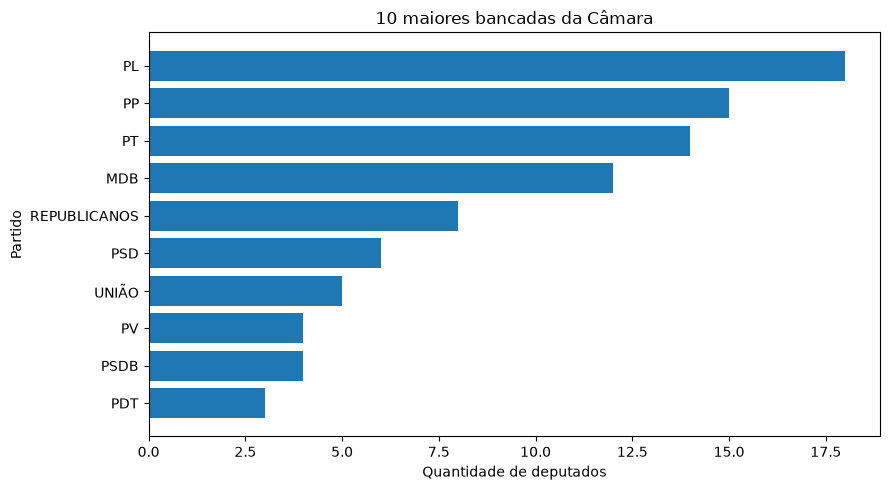

In [7]:
top_partidos = gold_partidos.head(10).sort_values("qtd_deputados")
plt.figure(figsize=(9, 5))
plt.barh(top_partidos["partido"], top_partidos["qtd_deputados"])
plt.title("10 maiores bancadas da Câmara")
plt.xlabel("Quantidade de deputados")
plt.ylabel("Partido")
plt.tight_layout()
plt.savefig(gold / "grafico_partidos.png", dpi=150)
plt.show()

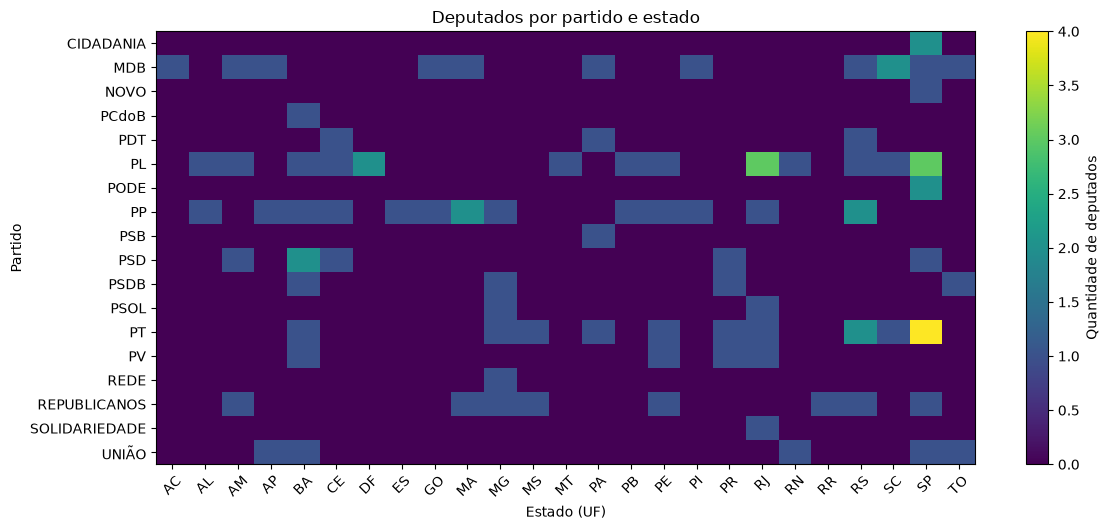

In [8]:
tabela = silver_df.pivot_table(
    index="partido", columns="uf", values="id", aggfunc="nunique", fill_value=0
)
plt.figure(figsize=(12, max(5, len(tabela) * 0.3)))
plt.imshow(tabela, aspect="auto")
plt.title("Deputados por partido e estado")
plt.xlabel("Estado (UF)")
plt.ylabel("Partido")
plt.xticks(range(len(tabela.columns)), tabela.columns, rotation=45)
plt.yticks(range(len(tabela.index)), tabela.index)
plt.colorbar(label="Quantidade de deputados")
plt.tight_layout()
plt.savefig(gold / "grafico_partido_uf.png", dpi=150)
plt.show()

In [11]:
with sqlite3.connect(gold / "camara.sqlite") as conexao:
    gold_partidos.to_sql("participacao_partidos", conexao, if_exists="replace", index=False)
    gold_partido_uf.to_sql("partido_por_uf", conexao, if_exists="replace", index=False)

    consulta = pd.read_sql_query(
        "SELECT partido, qtd_deputados, percentual "
        "FROM participacao_partidos "
        "ORDER BY qtd_deputados DESC LIMIT 5",
        conexao
    )

print("Cinco maiores bancadas:")
display(consulta)

Cinco maiores bancadas:


,partido,qtd_deputados,percentual
0,PL,18,18.0
1,PP,15,15.0
2,PT,14,14.0
3,MDB,12,12.0
4,REPUBLICANOS,8,8.0
